# Cross-seed replication of the information analyses

**Twenty paired seeds, forty networks.** Companion to `REPORT - Structure and Replication.md`.

This notebook is for checking the work, not for producing it. The full sweep is about four hours on sixteen
cores, so each method is instead **demonstrated live on one pair of networks**, where it runs in seconds, and
the twenty-seed result is loaded from stored per-network values and the statistics **recomputed here** rather
than read from a summary field. So the method can be verified by running it, and the claim by re-deriving it.

**What ships**

| | |
|---|---|
| `spike_caches/` | all forty binarised spike matrices, bit-packed |
| `code/` | every script that produced the results |
| `results/` | the result JSON, per-network values included |
| `figures/` | every figure in the report |
| `REPORT - ...md` | the write-up, with all figures and tables |
| `significance_tables.md` | full paired statistics, all three tests |
| `METHOD_NOTES.md` | where this departs from the original package, and why |

**Design.** Every comparison is paired within seed. The two networks of a seed share initial weights, data
order and training schedule; the only free difference is the hidden membrane time constant. Reported as
paired *t*, Wilcoxon, and an exact sign-flip permutation over all 2²⁰ sign assignments (floor 1.9×10⁻⁶).

In [1]:
import json, sys, itertools
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PKG = Path.cwd()
sys.path.insert(0, str(PKG / "code" / "supervisor_extension"))
sys.path.insert(0, str(PKG / "code" / "analysis_suite"))
from stats_core import paired_triple, signflip_p

SEEDS = [101, 202, 210, 340, 440, 550, 660, 710, 820, 930] + list(range(1001, 1011))
ARCHS = ("het", "hom")
HET, HOM = "#d1495b", "#30638e"
COL = {"het": HET, "hom": HOM}
LABEL = {"het": "heterogeneous", "hom": "homogeneous"}
R = lambda n: json.load(open(PKG / "results" / n))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
print("results available:", sorted(p.name for p in (PKG / "results").glob("*.json")))

results available: ['audit_fidelity.json', 'block_concentration_n20.json', 'block_k_sweep.json', 'capacity_corr_n20_summary.json', 'division_of_labour_n20.json', 'modularity_n20.json', 'rsi_n20.json', 'shattering_n20_summary.json', 'shattering_vs_rank_n20_summary.json', 'signal_dimension_n20_summary.json', 'structure_scalars_n20.json', 'summary.json', 'temporal_generalisation_n20_summary.json', 'temporal_lockin_n20.json', 'vc_shattering_n20_summary.json']


## 1. The data

Each cache is one network's hidden-layer spikes on the first 2048 SHD test trials, shape
`(64 units, 2048 trials, 250 samples)`, binary. Bit-packed for transport; `load_spikes` reverses it exactly.

Two facts about the cache that matter for interpretation, both inherited from the original pipeline:

- It is **strided sub-sampling, not binning**. The builder takes `spk[:, ::4, :]`, keeping every fourth 1 ms
  step rather than combining four. A cached count is therefore about a quarter of the true spike count.
  Nothing here is invalidated, since both arms go through the identical transform and every measure is
  null-corrected or paired, but absolute rates from this pipeline are not the networks' firing rates.
- The homogeneous partner differs by seed: seeds 202–930 use the no-weight-decay retrain, which is the one
  the clean design pairs.

In [2]:
def load_spikes(seed, arch, active_min=0.005):
    '''(n_active, 2048, 250) uint8 plus the indices of the kept units.'''
    z = np.load(PKG / "spike_caches" / f"4class_seed{seed}_{arch}_spk.npz")
    shape = tuple(z["shape"])
    a = np.unpackbits(z["packed"], axis=1)[:, :shape[1]]
    active = np.where(a.mean(1) >= active_min)[0]
    return a[active].reshape(len(active), 2048, 250), active

def labels():
    '''The three decision variables, aligned to the first 2048 rows of shd_test.h5.'''
    m = json.load(open(PKG / "spike_caches" / "MANIFEST.json"))
    y20 = np.array(m["_shd_labels"], int)
    return {"4-class": 2 * (y20 >= 10).astype(int) + (y20 % 10) % 2,
            "language": (y20 >= 10).astype(int),
            "parity": ((y20 % 10) % 2).astype(int)}

T = labels()
R3, act = load_spikes(1001, "het")
print(f"seed 1001 het: {R3.shape[0]} active units of 64, {R3.shape[1]} trials, {R3.shape[2]} samples")
print("class counts:", np.bincount(T["4-class"]))

seed 1001 het: 47 active units of 64, 2048 trials, 250 samples
class counts: [490 490 538 530]


### Alignment check

The cache ships no label vector, so a silent trial-order mismatch would produce a clean-looking but
meaningless analysis. A linear decode of the 4-class label from per-trial counts is the arbiter: aligned
caches land near 0.7–0.8, a misaligned one sits at the 0.25 chance line.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
import warnings; warnings.filterwarnings("ignore")

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
for arch in ARCHS:
    C, _ = (lambda r: (r[0].sum(2), r[1]))(load_spikes(1001, arch))
    acc = cross_val_score(clf, C.T, T["4-class"], cv=5).mean()
    print(f"  seed 1001 {arch}: 4-class decode {acc:.3f}  ({'aligned' if acc > .5 else 'CHANCE'})")
print("\n(all forty were checked this way; 0.636 to 0.841 against a 0.25 chance line)")

  seed 1001 het: 4-class decode 0.774  (aligned)


  seed 1001 hom: 4-class decode 0.681  (aligned)

(all forty were checked this way; 0.636 to 0.841 against a 0.25 chance line)


## 2. Modularity, and why the headline statistic fails here

The original claim is that the homogeneous co-activation graph is modular and the heterogeneous one is
near-random, measured as `Q/Q_rand` on the full graph: het 0.62 against hom 1.39 at seed 1001.

Below: build the graph live for one pair, then look at what twenty seeds say.

In [4]:
import networkx as nx

def mi_matrix(S):
    '''Zero-lag pairwise binary MI in bits, every pair at once. Float64 matters: in float32 the
    state probabilities can round negative and the logarithm returns NaN through the guard.'''
    n, N = S.shape
    p1 = S.mean(1); P11 = (S @ S.T) / N
    pi, pj = p1[:, None], p1[None, :]
    def term(pxy, px, py):
        with np.errstate(divide="ignore", invalid="ignore"):
            t = pxy * (np.log2(pxy) - np.log2(px * py))
        return np.where(pxy > 1e-15, t, 0.0)
    MI = (term(P11, pi, pj) + term(pi - P11, pi, 1 - pj)
          + term(pj - P11, 1 - pi, pj) + term(1 - pi - pj + P11, 1 - pi, 1 - pj))
    MI = np.clip(MI, 0, None); np.fill_diagonal(MI, 0.0)
    return MI

def circ_shift(Rt, rng):
    '''Independent circular shift per unit and trial: rate and within-trial autocorrelation survive,
    only cross-unit alignment is destroyed, which is what the edge is supposed to measure.'''
    n, TR, Tm = Rt.shape
    off = rng.integers(0, Tm, size=(n, TR)).astype(np.int32)
    idx = (np.arange(Tm, dtype=np.int32)[None, None, :] - off[:, :, None]) % Tm
    return np.take_along_axis(Rt, idx, axis=2).reshape(n, TR * Tm).astype(np.float64)

N_SURR = 20          # 100 in the full analysis; 20 is enough to see the structure
W = {}
for arch in ARCHS:
    Rt, _ = load_spikes(1001, arch)
    n = Rt.shape[0]
    obs = mi_matrix(Rt.reshape(n, -1).astype(np.float64))
    rng = np.random.default_rng(1001)
    null = np.mean([mi_matrix(circ_shift(Rt, rng)) for _ in range(N_SURR)], 0)
    W[arch] = np.clip(obs - null, 0, None); np.fill_diagonal(W[arch], 0)
    print(f"  {arch}: {n} units, mean edge MI {obs[np.triu_indices(n,1)].mean():.4f} bits, "
          f"null floor {100*null[np.triu_indices(n,1)].mean()/obs[np.triu_indices(n,1)].mean():.0f}% of it")

  het: 47 units, mean edge MI 0.0205 bits, null floor 13% of it


  hom: 42 units, mean edge MI 0.0123 bits, null floor 14% of it


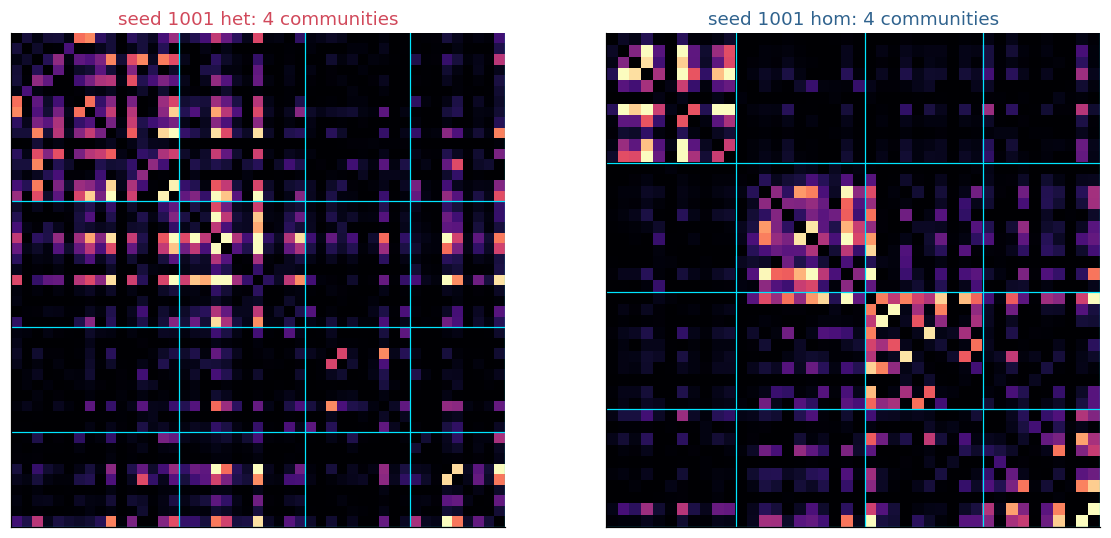

At this seed the homogeneous blocks are clear. The question is whether that generalises.


In [5]:
# community-ordered adjacency: the picture the original analysis leads with
def partition(Wm, seed):
    G = nx.Graph(); G.add_nodes_from(range(Wm.shape[0]))
    iu = np.triu_indices(Wm.shape[0], 1)
    for e in np.where(Wm[iu] > 0)[0]:
        G.add_edge(int(iu[0][e]), int(iu[1][e]), weight=float(Wm[iu][e]))
    part = sorted(nx.community.louvain_communities(G, weight="weight", seed=seed), key=len, reverse=True)
    mod = np.zeros(Wm.shape[0], int)
    for ci, c in enumerate(part):
        for v in c: mod[v] = ci
    return G, part, mod

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for i, arch in enumerate(ARCHS):
    G, part, mod = partition(W[arch], 1001)
    order = np.concatenate([np.where(mod == c)[0] for c in range(mod.max() + 1)])
    A = W[arch][np.ix_(order, order)]
    ax[i].imshow(A, cmap="magma", vmax=np.percentile(A[A > 0], 99))
    b = 0
    for c in part:
        b += len(c); ax[i].axhline(b - .5, color="#00e5ff", lw=.8); ax[i].axvline(b - .5, color="#00e5ff", lw=.8)
    ax[i].set_title(f"seed 1001 {arch}: {len(part)} communities", color=COL[arch]); ax[i].set_xticks([]); ax[i].set_yticks([])
plt.tight_layout(); plt.show()
print("At this seed the homogeneous blocks are clear. The question is whether that generalises.")

### It does not generalise on `Q/Q_rand`, and the reason is the statistic

At twenty seeds the comparison is a null, and three things point at the denominator rather than the networks:
seed 1001's homogeneous network is rank 20/20 in the distribution, the cumulative graph appears to reverse,
and **neither arm reaches 1.0** — which would mean the real graphs are less modular than their own
randomisations.

Two reasons `Q_rand` misbehaves here. On a graph at density 0.89 `double_edge_swap` cannot find legal moves
and raises, so the randomisation is mostly a weight permutation; and `Q_rand` is a *maximised* modularity over
random data, which is substantially positive on a graph this size (Guimerà et al. 2004).

In [6]:
mod = R("modularity_n20.json")
per = mod["per_network"]
V = lambda a, *path: np.array([_dig(per[f"{s}_{a}"], path) for s in SEEDS], float)
def _dig(d, path):
    for k in path: d = d[k]
    return d

rows = [("Full-graph Q/Q_rand", ("full", "Qnorm")), ("Cumulative-count Q/Q_rand", ("cumulative", "Qnorm")),
        ("Small-worldness sigma", ("full", "sigma"))]
print(f"{'':30} {'het':>7} {'hom':>7} {'delta':>8} {'d_z':>6} {'t':>9} {'W':>9} {'sign-flip':>10} wins")
for lbl, path in rows:
    r = paired_triple(V("het", *path), V("hom", *path))
    print(f"{lbl:30} {r['het_mean']:7.3f} {r['hom_mean']:7.3f} {r['delta']:+8.3f} {r['dz']:+6.2f} "
          f"{r['t_p']:9.3f} {r['w_p']:9.3f} {r['perm_p']:10.3f} {r['wins']}/{r['n']}")

q = np.array([_dig(per[f'{s}_hom'], ('full','Qnorm')) for s in SEEDS])
i = SEEDS.index(1001)
print(f"\nseed 1001 hom sits at z = {(q[i]-q.mean())/q.std(ddof=1):+.2f} in the hom distribution, "
      f"rank {int((q <= q[i]).sum())}/20")

                                   het     hom    delta    d_z         t         W  sign-flip wins


Full-graph Q/Q_rand              0.573   0.674   -0.101  -0.25     0.281     0.231      0.280 7/20


Cumulative-count Q/Q_rand        1.251   1.018   +0.233  +0.42     0.073     0.097      0.074 14/20


Small-worldness sigma            0.507   0.395   +0.111  +0.45     0.060     0.058      0.060 14/20

seed 1001 hom sits at z = +2.22 in the hom distribution, rank 20/20


### Without a null, the claim replicates

Ask what the block matrices actually show: is edge weight concentrated inside communities? Mean
within-community weight over mean between-community weight, no randomisation anywhere in it.

In [7]:
bc = R("block_concentration_n20.json")
print(f"{'':34} {'het':>6} {'hom':>6} {'delta':>7} {'d_z':>6} {'t':>9} {'W':>9} {'sign-flip':>10}  hom higher")
for k, lbl in [("louvain", "Louvain (binned graph)"), ("fixedK", "Fixed K = 3, spectral"),
               ("louvain_cum", "Louvain (cumulative graph)")]:
    h = np.array([bc["per_network"]["het"][str(s)][k] for s in SEEDS])
    o = np.array([bc["per_network"]["hom"][str(s)][k] for s in SEEDS])
    r = paired_triple(h, o)
    print(f"{lbl:34} {r['het_mean']:6.2f} {r['hom_mean']:6.2f} {r['delta']:+7.2f} {r['dz']:+6.2f} "
          f"{r['t_p']:9.5f} {r['w_p']:9.5f} {r['perm_p']:10.5f}  {r['n']-r['wins']}/{r['n']}")
print(f"\ncorr(this ratio, full-graph Q/Q_rand) over 40 networks = {bc['corr_ratio_vs_Qnorm']:+.2f}")
print("The headline statistic barely tracks the structure its own figures display.")

                                      het    hom   delta    d_z         t         W  sign-flip  hom higher


Louvain (binned graph)               2.98   4.59   -1.61  -0.99   0.00030   0.00013    0.00012  17/20


Fixed K = 3, spectral                4.08   7.14   -3.05  -0.97   0.00037   0.00121    0.00074  15/20


Louvain (cumulative graph)           1.93   2.54   -0.61  -0.79   0.00222   0.00143    0.00166  16/20

corr(this ratio, full-graph Q/Q_rand) over 40 networks = +0.21
The headline statistic barely tracks the structure its own figures display.


Localising it further: the two arms concentrate weight *within* communities to the same degree. What differs
is how much sits **between** them. So the homogeneous modules are not internally tighter, they are more
**isolated**. The sweep over K = 2..6 shows the between-community gap holds at every K while the
within-community difference fades, so the robust half is the between half.

See `figures/S17_aggregate_blocks.png` and `figures/S18_block_k_sweep.png`.

In [8]:
ks = R("block_k_sweep.json")
print(f"{'K':>3} | {'within p':>9} | {'between het':>11} {'between hom':>11} {'between p':>10}")
for K in ["2", "3", "4", "5", "6"]:
    w_, b_ = ks["by_k"][K]["within"], ks["by_k"][K]["between"]
    print(f"{K:>3} | {w_['perm_p']:9.3f} | {b_['het_mean']:11.3f} {b_['hom_mean']:11.3f} {b_['perm_p']:10.4f}")

  K |  within p | between het between hom  between p
  2 |     0.010 |       0.466       0.297     0.0054
  3 |     0.011 |       0.511       0.339     0.0015
  4 |     0.033 |       0.516       0.329     0.0023
  5 |     0.177 |       0.527       0.324     0.0013
  6 |     0.332 |       0.522       0.316     0.0012


## 3. Redundancy and synergy of the class information

Per trial each unit contributes one integer spike count, the feature the readout integrates. With the class
label as target and two sources, the MMI decomposition is
`R = min(I_i, I_j)`, `S = I_joint − max(I_i, I_j)`, `RSI = I_joint − I_i − I_j = S − R`.

Two corrections are load-bearing. Counts are integers with heavy ties, so kNN distances collapse and the
estimator returns NaN unless they are dithered. And subtracting two separately estimated kNN differential
entropies is biased, with a different bias in the 2-D joint than in the 1-D marginals, so without a
label-permutation null the joint MI comes out negative and synergy is meaningless.

In [9]:
res = R("rsi_n20.json")
print("unit of analysis: the network, not the pair.")
print("Pairs inside a network share units, training run and seed, so a Mann-Whitney over pairs has an")
print("effective n far below its nominal one and cannot speak about architectures.\n")
print(f"{'':36} {'het':>8} {'hom':>8} {'delta':>8} {'d_z':>6} {'t':>9} {'W':>9} {'sign-flip':>10} wins")
for k, lbl in [("I_joint", "Pair joint MI"), ("redundancy", "Redundancy"), ("synergy", "Synergy"),
               ("RSI", "RSI = synergy - redundancy"), ("redundancy_n", "Redundancy / I_joint"),
               ("RSI_n", "RSI / I_joint")]:
    h = np.array([res["per_network"][f"{s}_het"][k] for s in SEEDS])
    o = np.array([res["per_network"][f"{s}_hom"][k] for s in SEEDS])
    r = paired_triple(h, o)
    print(f"{lbl:36} {r['het_mean']:+8.4f} {r['hom_mean']:+8.4f} {r['delta']:+8.4f} {r['dz']:+6.2f} "
          f"{r['t_p']:9.4f} {r['w_p']:9.4f} {r['perm_p']:10.4f} {r['wins']}/{r['n']}")
print("\nScale replicates strongly. Net RSI in bits is a null, and the normalised balance leans homogeneous:")
print("under the original package's own active-unit rule that trend reaches p = 0.010 (see audit_fidelity).")

unit of analysis: the network, not the pair.
Pairs inside a network share units, training run and seed, so a Mann-Whitney over pairs has an
effective n far below its nominal one and cannot speak about architectures.

                                          het      hom    delta    d_z         t         W  sign-flip wins


Pair joint MI                         +0.4272  +0.3482  +0.0789  +0.98    0.0003    0.0001     0.0002 18/20


Redundancy                            +0.1352  +0.0995  +0.0357  +1.10    0.0001    0.0000     0.0001 17/20


Synergy                               +0.1776  +0.1470  +0.0305  +0.89    0.0008    0.0003     0.0003 16/20


RSI = synergy - redundancy            +0.0424  +0.0475  -0.0052  -0.15    0.5080    0.5459     0.5036 10/20


Redundancy / I_joint                  +0.3190  +0.2878  +0.0312  +0.77    0.0027    0.0023     0.0038 15/20


RSI / I_joint                         +0.0921  +0.1314  -0.0393  -0.45    0.0583    0.0696     0.0594 7/20

Scale replicates strongly. Net RSI in bits is a null, and the normalised balance leans homogeneous:
under the original package's own active-unit rule that trend reaches p = 0.010 (see audit_fidelity).


## 4. Timing, and the order in which the factors resolve

The claim is that the homogeneous network locks in language early and parity late, a clean sequence, while
the heterogeneous one integrates both late and together.

Two clocks are measured because they answer different questions. **Instantaneous**: when is information
momentarily present in the population state. **Accumulated**: when does the running spike count commit. The
lock-in time is the interpolated first crossing of ninety per cent of the asymptote; interpolation matters
because the grid spacing is 25 ms and the gap under test was 176 ms.

In [10]:
tl = R("temporal_lockin_n20.json")
tp = tl["per_network"]
print(f"{'':36} {'het':>7} {'hom':>7} {'delta':>8} {'d_z':>6} {'sign-flip':>10} wins")
for k, lbl in [("acc_4-class_lockin_ms", "4-class lock-in (ms)"),
               ("acc_language_lockin_ms", "Language lock-in (ms)"),
               ("acc_parity_lockin_ms", "Parity lock-in (ms)"),
               ("acc_gap_ms", "Gap (parity - language, ms)")]:
    h = np.array([tp[f"{s}_het"][k] for s in SEEDS]); o = np.array([tp[f"{s}_hom"][k] for s in SEEDS])
    r = paired_triple(h, o)
    print(f"{lbl:36} {r['het_mean']:7.1f} {r['hom_mean']:7.1f} {r['delta']:+8.1f} {r['dz']:+6.2f} "
          f"{r['perm_p']:10.4f} {r['wins']}/{r['n']}")

print("\nIs either arm ordered at all? (one-sample sign-flip on the twenty per-seed gaps)")
for arch in ARCHS:
    for k, lbl in [("acc_gap_ms", "accumulated lock-in"), ("inst_gap_ms", "instantaneous COM")]:
        g = np.array([tp[f"{s}_{arch}"][k] for s in SEEDS]); g = g[np.isfinite(g)]
        p, fl = signflip_p(g)
        print(f"  {arch} {lbl:22} mean {g.mean():+7.1f} ms   language-first {int((g>0).sum())}/{g.size}   p {p:.5f}")
print("\nThe homogeneous ordering is real. It is also a tendency, not a rule: 7 of 20 resolve parity first.")

                                         het     hom    delta    d_z  sign-flip wins


4-class lock-in (ms)                   550.9   430.7   +120.2  +0.76     0.0039 17/20


Language lock-in (ms)                  551.6   353.1   +198.5  +0.99     0.0005 17/20


Parity lock-in (ms)                    578.8   468.8   +110.0  +0.75     0.0041 17/20


Gap (parity - language, ms)             27.3   115.7    -88.5  -0.35     0.1318 8/20

Is either arm ordered at all? (one-sample sign-flip on the twenty per-seed gaps)


  het accumulated lock-in    mean   +27.3 ms   language-first 8/20   p 0.42460


  het instantaneous COM      mean   +63.6 ms   language-first 15/20   p 0.00120


  hom accumulated lock-in    mean  +115.7 ms   language-first 13/20   p 0.01505


  hom instantaneous COM      mean  +141.7 ms   language-first 18/20   p 0.00003

The homogeneous ordering is real. It is also a tendency, not a rule: 7 of 20 resolve parity first.


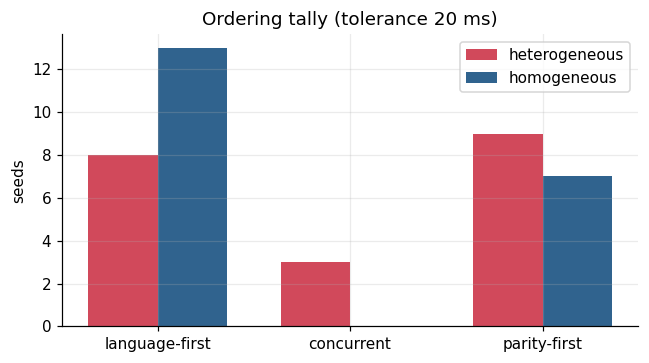

In [11]:
cnt = tl["order_counts"]
fig, ax = plt.subplots(figsize=(6, 3.4))
cats = ["language-first", "concurrent", "parity-first"]
x = np.arange(3); w = .36
for i, a in enumerate(ARCHS):
    ax.bar(x + (i - .5) * w, [cnt[a].get(c, 0) for c in cats], w, color=COL[a], label=LABEL[a])
ax.set_xticks(x); ax.set_xticklabels(cats); ax.set_ylabel("seeds"); ax.legend()
ax.set_title(f"Ordering tally (tolerance {tl['tolerance_ms']:.0f} ms)")
plt.tight_layout(); plt.show()

## 5. Division of labour across modules

Each unit is scored by its language and parity MI and given a scale-free selectivity index
`SI = (L − P)/(|L| + |P|)`. Division of labour means module identity explains SI. Because η² rises with the
number of groups even under the null, and the arms do not find the same number of communities, the excess
over each network's own permutation null is reported alongside it.

In [12]:
dol = R("division_of_labour_n20.json"); dp = dol["per_network"]
print(f"{'':38} {'het':>7} {'hom':>7} {'delta':>8} {'d_z':>6} {'t':>8} {'W':>8} {'sign-flip':>10} hom higher")
for k, lbl in [("eta2_SI_module", "eta2(selectivity ~ module)"),
               ("eta2_excess", "eta2 above its permutation null"),
               ("n_modules", "Number of modules")]:
    h = np.array([dp[f"{s}_het"][k] for s in SEEDS], float)
    o = np.array([dp[f"{s}_hom"][k] for s in SEEDS], float)
    r = paired_triple(h, o)
    print(f"{lbl:38} {r['het_mean']:7.3f} {r['hom_mean']:7.3f} {r['delta']:+8.3f} {r['dz']:+6.2f} "
          f"{r['t_p']:8.4f} {r['w_p']:8.4f} {r['perm_p']:10.4f}  {r['n']-r['wins']}/{r['n']}")
sig = dol["n_significant_within_network"]
print(f"\nWithin-network permutation tests reached p < 0.05 in {sig['hom']}/20 homogeneous and "
      f"{sig['het']}/20 heterogeneous networks (about 1/20 expected by chance).")
print("This replicates, and it survived while the modularity statistic underneath it did not.")

                                           het     hom    delta    d_z        t        W  sign-flip hom higher


eta2(selectivity ~ module)               0.113   0.211   -0.098  -0.58   0.0178   0.0215     0.0190  14/20


eta2 above its permutation null          0.059   0.160   -0.101  -0.61   0.0133   0.0153     0.0146  13/20


Number of modules                        3.500   3.100   +0.400  +0.40   0.0880   0.0829     0.1360  11/20

Within-network permutation tests reached p < 0.05 in 13/20 homogeneous and 5/20 heterogeneous networks (about 1/20 expected by chance).
This replicates, and it survived while the modularity statistic underneath it did not.


## 6. What replicated

| Axis | Original (n = 1) | At n = 20 |
|---|---|---|
| Class information per unit and pair | het higher | **replicates**, d_z 0.9–1.1 |
| Redundancy and synergy, in bits | both higher in het | **replicates**, 16–17/20 |
| Net RSI, in bits | het higher | **null**, 10/20 |
| Redundancy–synergy balance | invariant | leans homogeneous |
| Integration timescale | het longer | **replicates**, 17/20 |
| hom language before parity | clean sequence | **holds, 13/20, p = 0.015**, modal not universal |
| Functional graph modularity | hom modular | **replicates** by weight concentration, effect size inflated |
| `Q/Q_rand` as a statistic | the headline | **unreliable here**, tracks block structure at r = 0.21 |
| Module double dissociation | language vs parity | **half**: language real, parity a null |
| Division of labour by module | hom yes, het no | **replicates**, p = 0.015–0.019 |

The picture survives twenty seeds. The headline *number* does not, because `Q/Q_rand` is the wrong instrument
for a graph this dense.

**Audits.** `audit_numerics.py` (zero non-finite values anywhere; float32 against float64 agrees to 2.7e-07
bits; the division-of-labour partitions are identical to the modularity partitions on 40/40 networks) and
`audit_fidelity.py` (every conclusion unchanged under the original package's own active-unit rule and null
count). Both are in `code/supervisor_extension/` and can be re-run.

**Not extended.** seqNMF, higher-order MaxEnt, discrete PID, and the `info_processing` notebooks.